# Fish × signed-electrode gains of my model in the camera tank (71 recordings, 1000 best clean EODs per fish)

**EODs.** From the clean emitter set of all 71 recordings (`EOD_clean_emitter_set_71_videos_denis_4fish_kaden.ipynb`: good masks,
emitter ≥ 10 cm from the others, lowest shape L2 in Denis' model, its 2 nearest pairs = the 2 loudest recorded pairs with his
sign, other fish ≤ ½ his predicted |v| there), per fish the 1000 with the smallest shape L2, spread as evenly as possible over
the nearest electrode pairs (`best1000_per_fish_71.csv`).

**My model** (`kaden_4fish_tank_model.py`): the tank outline fitted to the camera background, electrodes moved inside the walls,
the four plastic L-pieces of the inner square as non-conductive barriers, the other fish with skin and an interior of 4 × water,
unit current, sink at the tail tip, N 150, Kaden's masks and the mask midline of the EOD's own frame. Model sign: MODEL_SIGN × u.

**Ratios.** Recorded = the main-phase pattern (all 10 pairs at the sample of the largest |V|, traces demeaned). For each EOD the
2 pairs with the largest recorded |V|, and on each $g = |V_\text{rec}| / |V_\text{pred}|$ for the emitter. Left out: wrong sign,
or |predicted| < 5% of the emitter's largest predicted |v|. Each ratio is put under the electrode of its pair (+ or −) nearer to the
emitter's midline (20 signed electrodes).

**Fits.**
- Least squares on the ratios, 4 fish factors × 20 signed-electrode factors (each electrode factor the same for all fish;
  alternating least squares, electrode factors scaled to a geometric mean of 1).
- **Median factors** (what the voltage rule uses): fish factor = median of that fish's ratios; electrode factor = median of
  $g / a_f$ over the ratios at that electrode (an electrode without ratios gets 1).
- Fish factor vs fish length (A 15.65, B 13.10, C 9.82, D 8.51 cm): linear and power law through the 4 fish factors, 95%
  bootstrap intervals (2000 resamples of EODs).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import TwoSlopeNorm
from eod_assign import load_electrode_pairs, recorded_pair_traces_all, MODEL_SIGN
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
SRC = f'{BASE}/clean_emitter_set_71'
OUT = f'{SRC}/gain_mine_tank_int4'; os.makedirs(OUT, exist_ok=True)
TAG = 'model_N150_tank_barriers_int4_best1000.pkl'
EL_FILE = 'data/electrodes/electrode_locations_updated_4-fish.csv'
EL = pd.read_csv(EL_FILE); PIDS = [p for p, _, _ in load_electrode_pairs(EL_FILE, P)]
POLE = {int(r.pair): (((r.x1, r.y1), (r.x2, r.y2)) if str(r.pol1).strip() == '+' else ((r.x2, r.y2), (r.x1, r.y1))) for _, r in EL.iterrows()}
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
POLE_COL = {'+': '#33332F', '−': '#B5B5AF'}
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}; LF = np.array([L_CM[f] for f in LET])
ORDER = [f'{p}{s}' for p in range(1, 11) for s in ('+', '−')]
NTOP, MIN_FRAC, NBOOT = 2, 0.05, 2000
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})

S = pd.read_csv(f'{SRC}/best1000_per_fish_71.csv')
rows, AGREE = [], []
for t, g in S.groupby('video'):
    U = pd.read_pickle(f'{BASE}/{t}/{TAG}')
    keep = set(g.row.tolist())
    df = pd.read_csv(f'data/4 fish/Data_4fish_2024-02-20T{t}.csv', usecols=[f'electrode_{p}_time_{i}' for p in PIDS for i in range(1, 26)],
                     skiprows=lambda i: i > 0 and (i - 1) not in keep)
    V = recorded_pair_traces_all(df, PIDS, 25); del df
    ts = np.abs(V).max(1).argmax(1); R = V[np.arange(len(V)), :, ts]                      # main-phase pattern, rows in sorted order
    z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {int(k): i for i, k in enumerate(z['frames'])}; mids = z['mids']
    for (_, r), rec in zip(g.sort_values('row').iterrows(), R):
        j = LET.index(r.fish); Uf = MODEL_SIGN * U[int(r.Frame)]; u = Uf[j]
        l2 = [np.linalg.norm(Uf[h] / np.abs(Uf[h]).max() - rec / np.abs(rec).max()) if np.isfinite(Uf[h]).all() else np.inf for h in range(4)]
        AGREE.append(dict(video=t, row=r.row, fish=r.fish, mine_pick=LET[int(np.argmin(l2))], mine_L2_emitter=l2[j],
                          mine_L2_next=np.sort(np.delete(l2, j))[0]))
        xy = mids[gi[int(r.Frame)], j] * (P - 1)                                             # (101, row/col) px
        for rank, p in enumerate(np.argsort(-np.abs(rec))[:NTOP]):
            (px, py), (mx, my) = POLE[p + 1]
            dp, dm = np.hypot(xy[:, 1] - px, xy[:, 0] - py).min(), np.hypot(xy[:, 1] - mx, xy[:, 0] - my).min()
            rows.append(dict(video=t, row=r.row, Frame=r.Frame, fish=r.fish, L2_denis=r.L2_fish, pair=p + 1, rank=rank + 1,
                             rec=rec[p], pred=u[p], gain=abs(rec[p]) / abs(u[p]), same_sign=np.sign(rec[p]) == np.sign(u[p]),
                             pred_frac=abs(u[p]) / np.abs(u).max(), electrode=f'{p + 1}{"+" if dp < dm else "−"}', dist_cm=min(dp, dm) / (P / 60)))
AG = pd.DataFrame(AGREE); AG.to_csv(f'{OUT}/my_model_shape_check_best1000.csv', index=False)
print("my model's shape rule (main phase, L2, max |v| = 1) picks the same emitter as the selection (Denis' model):",
      {f: f'{(g_.mine_pick == f).mean() * 100:.1f}%' for f, g_ in AG.groupby('fish')}, f'all {(AG.mine_pick == AG.fish).mean() * 100:.1f}%')
D = pd.DataFrame(rows); D['kept'] = D.same_sign & (D.pred_frac >= MIN_FRAC)
D['eod'] = D.groupby(['video', 'row']).ngroup()
D.to_csv(f'{OUT}/ratios_best1000.csv', index=False)
print(f'{D.eod.nunique()} EODs, {len(D)} ratios; left out {(~D.same_sign).sum()} wrong sign, '
      f'{(D.same_sign & (D.pred_frac < MIN_FRAC)).sum()} |pred| < {MIN_FRAC:.0%}; kept {D.kept.sum()}')
display(pd.crosstab(D[D.kept].fish, D[D.kept].electrode).reindex(columns=[e for e in ORDER if e in set(D.electrode)]))
D = D[D.kept].reset_index(drop=True)

my model's shape rule (main phase, L2, max |v| = 1) picks the same emitter as the selection (Denis' model): {'A': '100.0%', 'B': '100.0%', 'C': '100.0%', 'D': '100.0%'} all 100.0%
4000 EODs, 8000 ratios; left out 2 wrong sign, 1 |pred| < 5%; kept 7997


electrode,1+,1−,2+,2−,3+,3−,4+,4−,5+,5−,6+,6−,7+,7−,8+,8−,9+,9−,10+,10−
fish,,,,,,,,,,,,,,,,,,,,
A,32,161,83,32,54,71,150,54,63,80,87,69,45,150,103,43,180,158,140,245
B,152,198,83,152,82,102,0,83,3,1,111,7,29,178,101,23,209,2,185,299
C,15,92,107,15,130,85,28,131,86,44,164,86,124,131,14,123,77,61,192,294
D,21,94,141,21,174,109,19,173,84,36,215,85,102,139,50,102,80,37,97,219


In [2]:
def fit_ls(g, fi, ki, nk=20, iters=300):
    a, e = np.ones(4), np.ones(nk)
    nf = np.bincount(fi, minlength=4) > 0; ne = np.bincount(ki, minlength=nk) > 0
    for _ in range(iters):
        ee = e[ki]; a = np.where(nf, np.bincount(fi, g * ee, 4) / np.maximum(np.bincount(fi, ee * ee, 4), 1e-300), np.nan)
        aa = a[fi]; e = np.where(ne, np.bincount(ki, g * aa, nk) / np.maximum(np.bincount(ki, aa * aa, nk), 1e-300), np.nan)
    c = np.exp(np.nanmean(np.log(e))); return a * c, e / c

def fit_median(g, fi, ki, nk=20):
    a = np.array([np.median(g[fi == j]) if (fi == j).any() else np.nan for j in range(4)])
    e = np.array([np.median(g[ki == k] / a[fi[ki == k]]) if (ki == k).any() else np.nan for k in range(nk)])
    return a, e

def arrays(d): return d.gain.to_numpy(), d.fish.map(LET.index).to_numpy(), d.electrode.map({e: i for i, e in enumerate(ORDER)}).to_numpy()
def r2(y, yh): return 1 - ((y - yh) ** 2).sum() / ((y - y.mean()) ** 2).sum()

g, fi, ki = arrays(D)
A_LS, E_LS = fit_ls(g, fi, ki); A_MED, E_MED = fit_median(g, fi, ki)
n_e = np.bincount(ki, minlength=20)
print(f'R² of the ratios: least squares {r2(g, A_LS[fi] * E_LS[ki]) * 100:.1f}%, median factors {r2(g, A_MED[fi] * E_MED[ki]) * 100:.1f}%')
F = pd.DataFrame({'least squares': np.r_[A_LS, E_LS], 'median': np.r_[A_MED, E_MED],
                  'n ratios': np.r_[np.bincount(fi, minlength=4), n_e]}, index=[f'fish {f}' for f in LET] + [f'electrode {e}' for e in ORDER])
F.to_csv(f'{OUT}/fish_and_signed_electrode_factors.csv'); display(F.round(4))
# what the voltage rule uses: median factors, electrodes without ratios -> 1
pd.DataFrame({'factor': [f'fish {f}' for f in LET] + [f'electrode {e}' for e in ORDER],
              'value': np.r_[A_MED, np.nan_to_num(E_MED, nan=1.0)], 'n_ratios': np.r_[np.bincount(fi, minlength=4), n_e]}).to_csv(f'{OUT}/voltage_rule_factors_median.csv', index=False)

R² of the ratios: least squares 73.9%, median factors 71.0%


,least squares,median,n ratios
fish A,0.3654,0.3479,2000
fish B,0.2619,0.2787,2000
fish C,0.3769,0.4052,1999
fish D,0.2580,0.2699,1998
electrode 1+,1.2154,1.1017,220
electrode 1−,0.8184,0.7533,545
electrode 2+,0.6673,0.6471,414
electrode 2−,1.1953,1.1613,220
electrode 3+,0.9923,0.9009,440
electrode 3−,0.6026,0.5784,367


## Fish factor vs fish length (each ratio a dot)

,least squares,median factors
fish A,"0.3654 [0.3614, 0.3691]","0.3479 [0.3325, 0.362]"
fish B,"0.2619 [0.2587, 0.2653]","0.2787 [0.2689, 0.2891]"
fish C,"0.3769 [0.3719, 0.382]","0.4052 [0.3898, 0.4192]"
fish D,"0.258 [0.254, 0.2619]","0.2699 [0.2607, 0.2804]"
slope s (per cm),"0.006075 [0.005301, 0.006868]","0.001607 [-0.0006611, 0.003641]"
intercept c,"0.2441 [0.2339, 0.2537]","0.3065 [0.2818, 0.3341]"
exponent e,"0.2336 [0.2051, 0.2648]","0.09555 [0.01096, 0.1653]"
k,"0.1758 [0.1626, 0.189]","0.2542 [0.2144, 0.3127]"


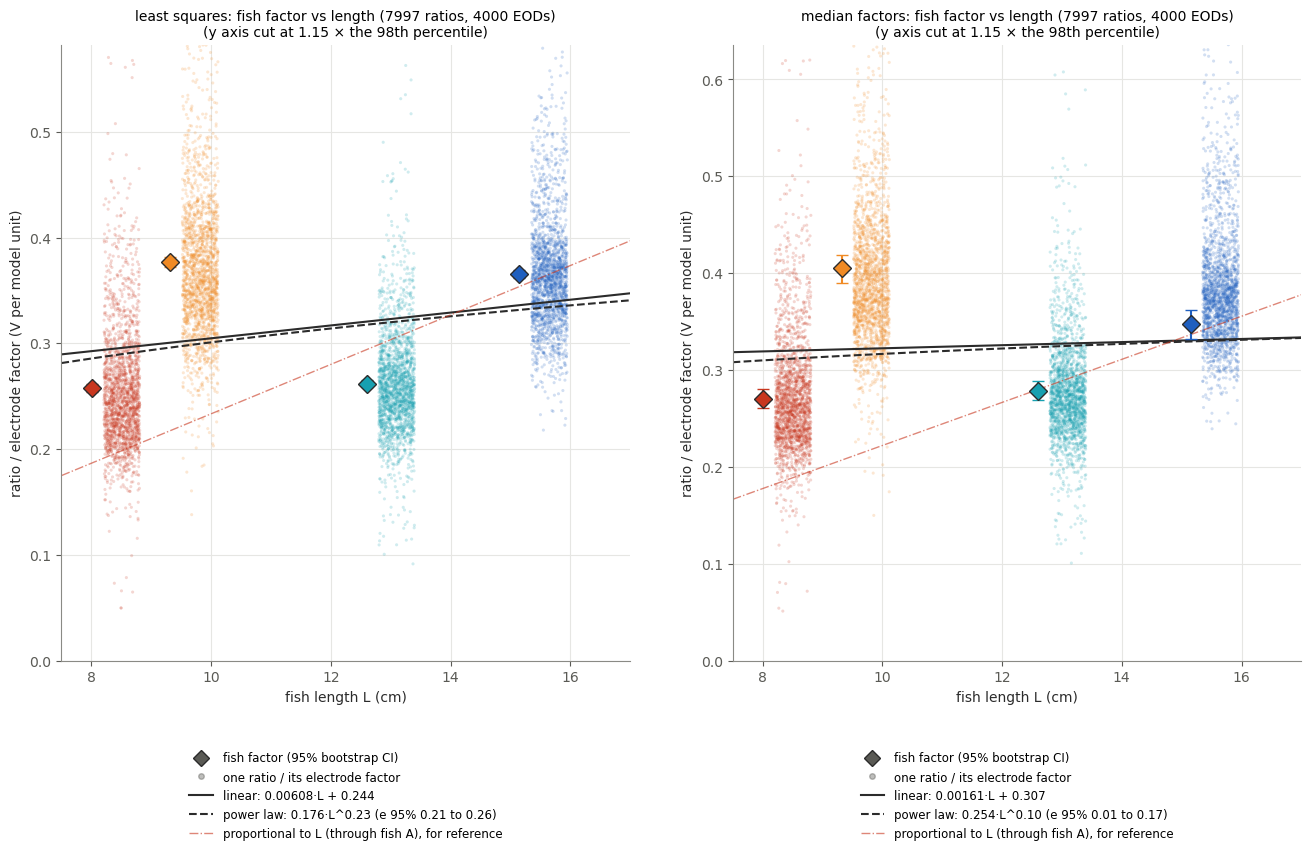

In [3]:
def length_fits(x, y):
    ok = np.isfinite(y) & (y > 0); s, c = np.polyfit(x[ok], y[ok], 1); e_, lk = np.polyfit(np.log(x[ok]), np.log(y[ok]), 1)
    return np.array([s, c, e_, np.exp(lk)])
rng = np.random.default_rng(0); grp = list(D.groupby('eod').indices.values()); B = []
for _ in range(NBOOT):
    bi = np.concatenate([grp[i] for i in rng.integers(0, len(grp), len(grp))]); gb, fb, kb = g[bi], fi[bi], ki[bi]
    ab, _ = fit_ls(gb, fb, kb, iters=150); am, _ = fit_median(gb, fb, kb)
    B.append(np.r_[ab, length_fits(LF, ab), am, length_fits(LF, am)])
B = np.array(B); lo, hi = np.nanpercentile(B, [2.5, 97.5], axis=0)
EST = np.r_[A_LS, length_fits(LF, A_LS), A_MED, length_fits(LF, A_MED)]
NAMES = [f'fish {f}' for f in LET] + ['slope s (per cm)', 'intercept c', 'exponent e', 'k']
T = pd.DataFrame({m: [f'{EST[o + k]:.4g} [{lo[o + k]:.4g}, {hi[o + k]:.4g}]' for k in range(8)] for m, o in (('least squares', 0), ('median factors', 8))}, index=NAMES)
T.to_csv(f'{OUT}/fish_factors_and_length_fits.csv'); display(T)

fig, axs = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw=dict(wspace=0.18))
xs = np.linspace(7.5, 17, 100); jit = np.random.default_rng(1)
for ax, (nm, a, e, o) in zip(axs, (('least squares', A_LS, E_LS, 0), ('median factors', A_MED, E_MED, 8))):
    y = g / np.where(np.isfinite(e[ki]), e[ki], 1.0); s, c, ex, k = EST[o + 4:o + 8]
    for j, f in enumerate(LET):
        kk = fi == j
        ax.scatter(LF[j] + jit.uniform(-0.3, 0.3, kk.sum()), y[kk], s=5, alpha=0.2, color=FISH_COL[f], edgecolor='none', zorder=2)
        ax.errorbar(LF[j] - 0.5, a[j], yerr=[[a[j] - lo[o + j]], [hi[o + j] - a[j]]], fmt='D', ms=9, color=FISH_COL[f], mec='#2b2b2b', capsize=4, zorder=4)
    ax.plot(xs, s * xs + c, color='#2b2b2b', lw=1.5, label=f'linear: {s:.3g}·L {"+" if c >= 0 else "−"} {abs(c):.3g}')
    ax.plot(xs, k * xs ** ex, color='#2b2b2b', lw=1.5, ls='--', label=f'power law: {k:.3g}·L^{ex:.2f} (e 95% {lo[o + 6]:.2f} to {hi[o + 6]:.2f})')
    ax.plot(xs, a[0] * xs / LF[0], color='#C8361E', lw=1, ls='-.', alpha=0.6, label='proportional to L (through fish A), for reference')
    ax.set(xlim=(7.5, 17), ylim=(0, np.percentile(y, 98) * 1.15), xlabel='fish length L (cm)', ylabel='ratio / electrode factor (V per model unit)')
    ax.set_title(f'{nm}: fish factor vs length ({len(D)} ratios, {D.eod.nunique()} EODs)\n(y axis cut at 1.15 × the 98th percentile)', fontsize=10)
    h = [Line2D([], [], marker='D', ls='', ms=8, color='#5a5a55', mec='#2b2b2b', label='fish factor (95% bootstrap CI)'),
         Line2D([], [], marker='o', ls='', ms=4, color='#5a5a55', alpha=0.4, label='one ratio / its electrode factor')]
    ax.legend(handles=h + ax.get_legend_handles_labels()[0], frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.13))
fig.savefig(f'{OUT}/fish_factor_vs_length.png', dpi=110, bbox_inches='tight'); plt.show()

## Signed-electrode factors

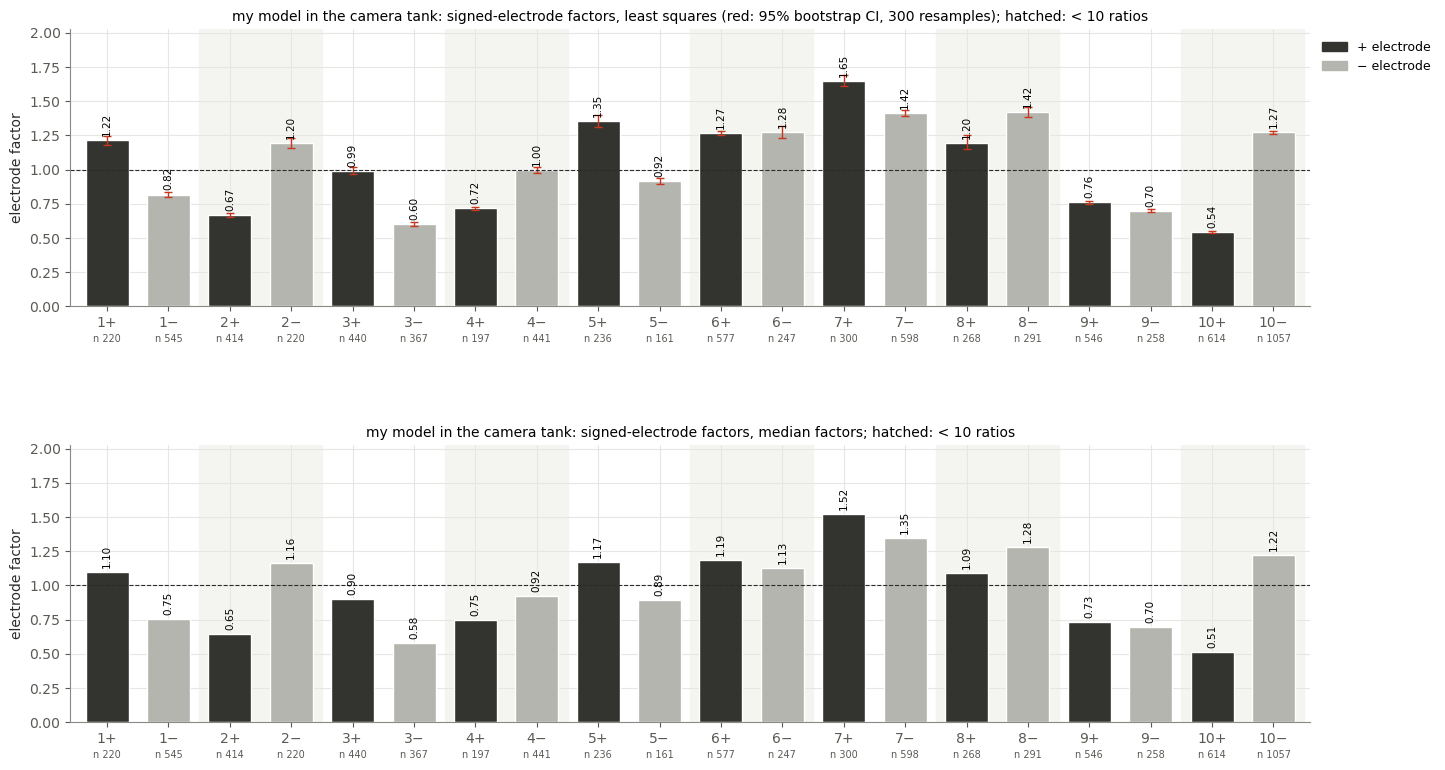

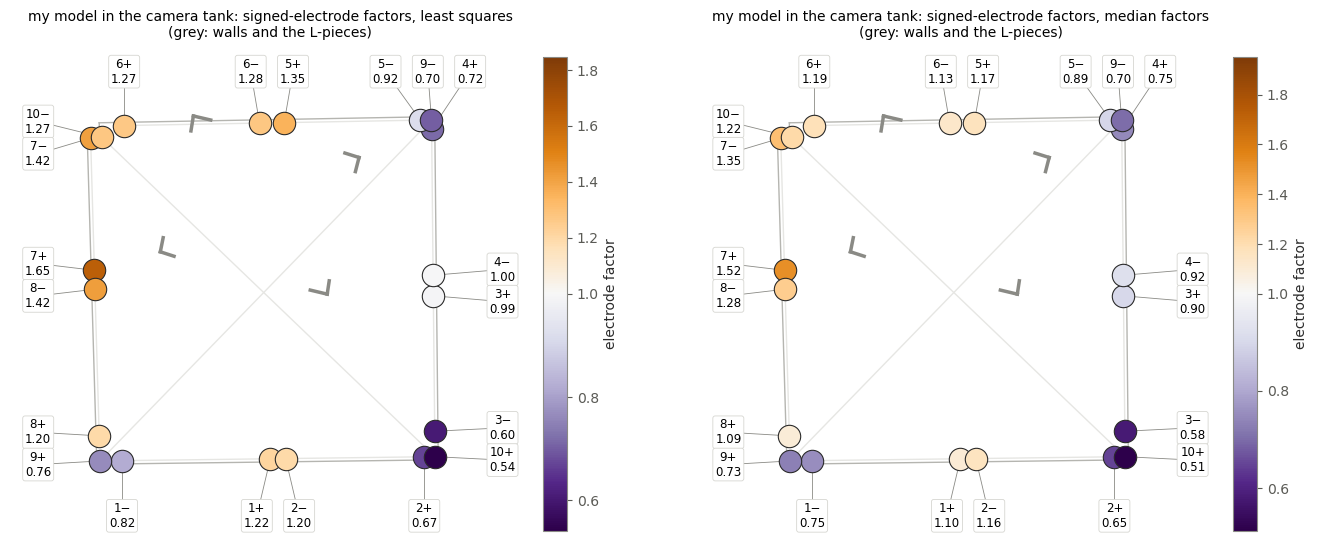

In [4]:
EL_XY = {}
for _, r in EL.iterrows():
    for x, y, s in ((r.x1, r.y1, str(r.pol1).strip()), (r.x2, r.y2, str(r.pol2).strip())): EL_XY[f'{int(r.pair)}{"+" if s == "+" else "−"}'] = (x, y)
lo_e = np.nanpercentile(np.array([fit_ls(g[bi], fi[bi], ki[bi], iters=150)[1] for bi in
                                  (np.concatenate([grp[i] for i in rng.integers(0, len(grp), len(grp))]) for _ in range(300))]), [2.5, 97.5], axis=0)
fig, axs = plt.subplots(2, 1, figsize=(16, 9), gridspec_kw=dict(hspace=0.5))
for ax, (nm, e) in zip(axs, (('least squares (red: 95% bootstrap CI, 300 resamples)', E_LS), ('median factors', E_MED))):
    x = np.arange(20); bars = ax.bar(x, np.nan_to_num(e), 0.7, color=[POLE_COL[el[-1]] for el in ORDER], edgecolor='white')
    for b_, nn in zip(bars, n_e):
        if nn < 10: b_.set_hatch('///'); b_.set_alpha(0.45)
    if e is E_LS:
        ok = np.isfinite(e); ax.errorbar(x[ok], e[ok], yerr=[e[ok] - lo_e[0][ok], lo_e[1][ok] - e[ok]], fmt='none', color='#C8361E', capsize=3, lw=1)
    for xi, v, nn in zip(x, e, n_e):
        ax.text(xi, (v if np.isfinite(v) else 0) + 0.03, f'{v:.2f}' if np.isfinite(v) else 'no data', ha='center', va='bottom', fontsize=7.5, rotation=90 if np.isfinite(v) else 0)
        ax.text(xi, -0.1, f'n {nn}', transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=7, color='#5a5a55')
    for p in range(10):
        if p % 2: ax.axvspan(2 * p - 0.5, 2 * p + 1.5, color='#f4f4f1', zorder=0)
    ax.axhline(1, color='#2b2b2b', lw=0.8, ls='--')
    ax.set(xticks=x, xlim=(-0.6, 19.6), ylim=(0, np.nanmax(np.r_[e, lo_e[1]]) * 1.2), ylabel='electrode factor')
    ax.set_xticklabels(ORDER); ax.set_title(f'my model in the camera tank: signed-electrode factors, {nm}; hatched: < 10 ratios', fontsize=10)
axs[0].legend(handles=[Patch(color=POLE_COL['+'], label='+ electrode'), Patch(color=POLE_COL['−'], label='− electrode')],
              frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.savefig(f'{OUT}/signed_electrode_factors.png', dpi=110, bbox_inches='tight'); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(17, 8.2), gridspec_kw=dict(wspace=0.1))
cmap = plt.get_cmap('PuOr_r'); BAR = pd.read_csv('data/electrodes/tank_barriers_4-fish.csv'); OUTL = pd.read_csv('data/electrodes/tank_outline_updated_4-fish.csv')
for ax, (nm, e) in zip(axs, (('least squares', E_LS), ('median factors', E_MED))):
    ev = dict(zip(ORDER, e)); fin = e[np.isfinite(e)]; span = max(abs(np.log2(fin.min())), abs(np.log2(fin.max())), 0.3)
    norm = TwoSlopeNorm(vmin=2 ** -span, vcenter=1, vmax=2 ** span)
    ax.plot(*np.vstack([OUTL[['x', 'y']].to_numpy(), OUTL[['x', 'y']].to_numpy()[:1]]).T, color='#b5b5b0', lw=1)
    for _, r in BAR.iterrows(): ax.plot([r.x1, r.x2], [r.y1, r.y2], color='#8a8a85', lw=2.5)
    for _, r in EL.iterrows(): ax.plot([r.x1, r.x2], [r.y1, r.y2], color='#e6e6e3', lw=1, zorder=1)
    LAB = {}
    for el, (x, y) in EL_XY.items():
        v = ev[el]
        if np.isfinite(v): ax.scatter(x, y, s=260, color=cmap(norm(v)), edgecolor='#2b2b2b', lw=0.8, zorder=3); LAB[el] = f'{el}\n{v:.2f}'
        else: ax.scatter(x, y, s=260, facecolor='white', edgecolor='#b5b5b0', lw=1, zorder=3, hatch='///'); LAB[el] = f'{el}\nno data'
    wall = {el: min((('top', y), ('bottom', P - y), ('left', x), ('right', P - x)), key=lambda q: q[1])[0] for el, (x, y) in EL_XY.items()}
    for w, gap, off in (('top', 105, -95), ('bottom', 105, P + 95), ('left', 80, -120), ('right', 80, P + 120)):
        els = sorted([el for el in EL_XY if wall[el] == w], key=lambda el: EL_XY[el][0] if w in ('top', 'bottom') else EL_XY[el][1])
        pos = [EL_XY[el][0] if w in ('top', 'bottom') else EL_XY[el][1] for el in els]
        for _ in range(50):
            for i in range(1, len(pos)):
                if pos[i] - pos[i - 1] < gap: mid = (pos[i] + pos[i - 1]) / 2; pos[i - 1], pos[i] = mid - gap / 2, mid + gap / 2
        for el, q in zip(els, pos):
            lx, ly = (q, off) if w in ('top', 'bottom') else (off, q)
            ax.plot([EL_XY[el][0], lx], [EL_XY[el][1], ly], color='#8a8a85', lw=0.6, zorder=2)
            ax.text(lx, ly, LAB[el], ha='center', va='center', fontsize=8.5, zorder=4, bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='#d6d6d1', lw=0.6))
    ax.set(xlim=(-190, P + 190), ylim=(P + 160, -160), aspect='equal', xticks=[], yticks=[]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_title(f'my model in the camera tank: signed-electrode factors, {nm}\n(grey: walls and the L-pieces)', fontsize=10)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.75, pad=0.02, label='electrode factor')
fig.savefig(f'{OUT}/signed_electrode_factors_tank_map.png', dpi=110, bbox_inches='tight'); plt.show()